In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv("../data/processed/cleaned_data.csv")

print("Dataset shape:", df.shape)

Dataset shape: (50000, 30)


In [4]:
df.head()
df.info()
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 30 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Customer_ID                 50000 non-null  object 
 1   Age                         50000 non-null  int64  
 2   Gender                      50000 non-null  object 
 3   Annual_Income               50000 non-null  int64  
 4   Occupation                  50000 non-null  object 
 5   Card_Type                   50000 non-null  object 
 6   Credit_Limit                50000 non-null  float64
 7   Card_Age_Months             50000 non-null  int64  
 8   Monthly_Spending            50000 non-null  float64
 9   Monthly_Transactions        50000 non-null  int64  
 10  Avg_Transaction_Value       50000 non-null  float64
 11  Online_Shopping_Spending    50000 non-null  float64
 12  Grocery_Spending            50000 non-null  float64
 13  Fuel_Spending               500

,count,mean,std,min,25%,50%,75%,max
Age,50000.0,3.608364e+01,1.223570e+01,18.00,27.0000,34.000,4.400000e+01,70.00
Annual_Income,50000.0,1.479318e+06,1.407257e+06,100050.00,657774.2500,1127629.500,1.663624e+06,7995831.00
Credit_Limit,50000.0,7.096772e+05,1.009854e+06,16000.00,157000.0000,396000.000,7.790000e+05,6591000.00
Card_Age_Months,50000.0,5.363200e+01,3.119581e+01,1.00,31.0000,48.000,7.000000e+01,240.00
Monthly_Spending,50000.0,7.387180e+04,8.433827e+04,2235.63,26646.4900,50022.385,8.302996e+04,691687.96
Monthly_Transactions,50000.0,8.303542e+01,4.204872e+01,15.00,49.0000,76.000,1.080000e+02,179.00
Avg_Transaction_Value,50000.0,8.359928e+02,7.795862e+02,57.76,448.3750,617.165,9.012550e+02,10463.06
Online_Shopping_Spending,50000.0,1.123828e+04,1.659942e+04,13.85,2800.6975,6163.210,1.282020e+04,258176.00
Grocery_Spending,50000.0,1.779428e+04,2.369766e+04,83.81,5176.9675,10651.410,2.041957e+04,352971.49
Fuel_Spending,50000.0,1.021273e+04,1.550964e+04,10.95,2432.1600,5466.360,1.156076e+04,235635.14


In [5]:
numeric_cols = df.select_dtypes(include=["int64", "float64"]).columns.tolist()

categorical_cols = df.select_dtypes(include=["object", "category"]).columns.tolist()

print("Numerical columns:", len(numeric_cols))
print("Categorical columns:", len(categorical_cols))

Numerical columns: 26
Categorical columns: 4


In [6]:
if "Customer_ID" in categorical_cols:
    categorical_cols.remove("Customer_ID")

print("Categorical columns:", categorical_cols)

Categorical columns: ['Gender', 'Occupation', 'Card_Type']


In [7]:
eda_numeric_cols = [
    "Age",
    "Annual_Income",
    "Credit_Limit",
    "Monthly_Spending",
    "Monthly_Transactions",
    "Avg_Transaction_Value",
    "Outstanding_Balance",
    "Statement_Balance",
    "Payment_Amount",
    "Payment_Ratio",
    "Credit_Utilization",
    "Credit_Score"
]

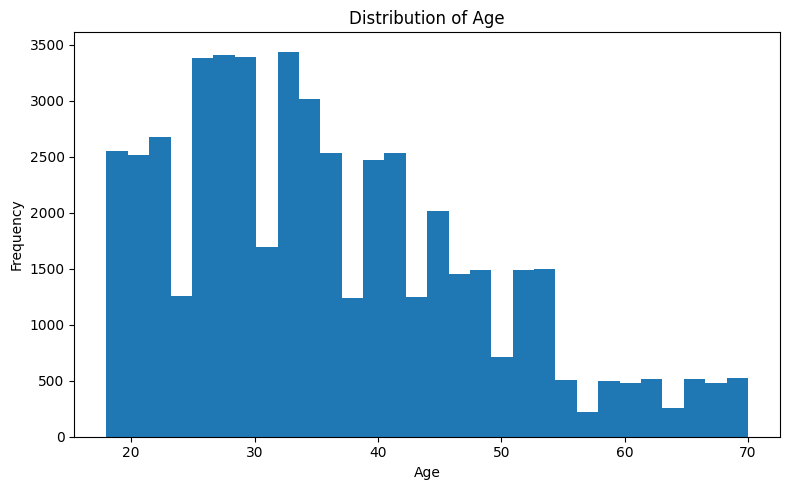

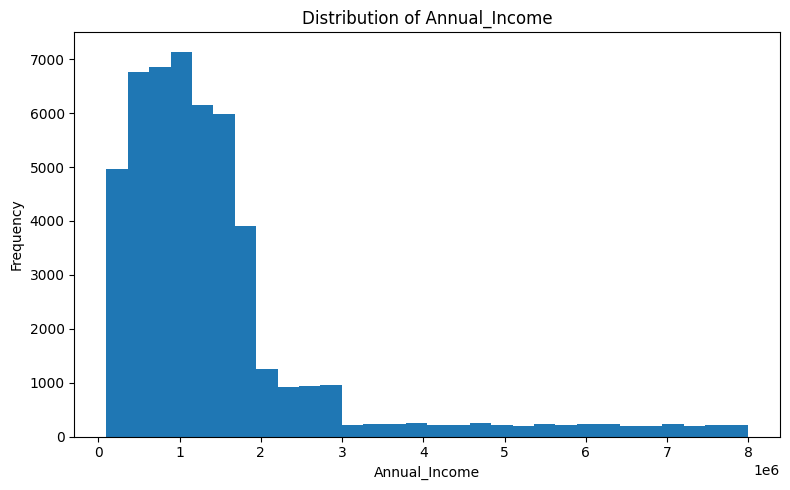

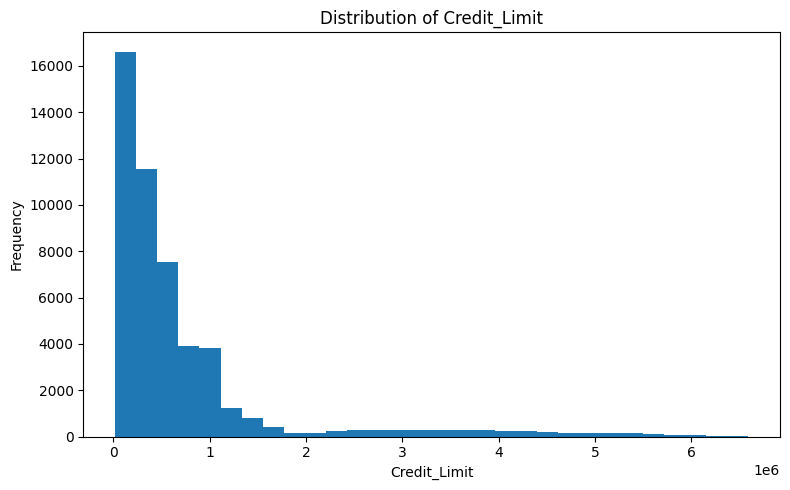

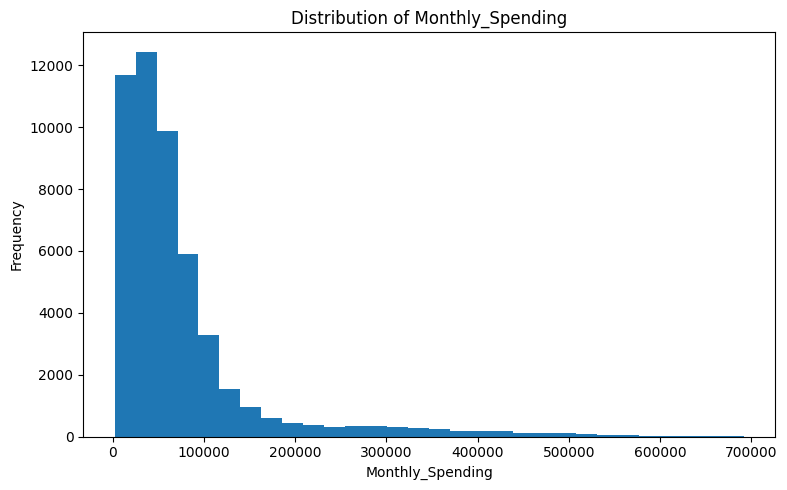

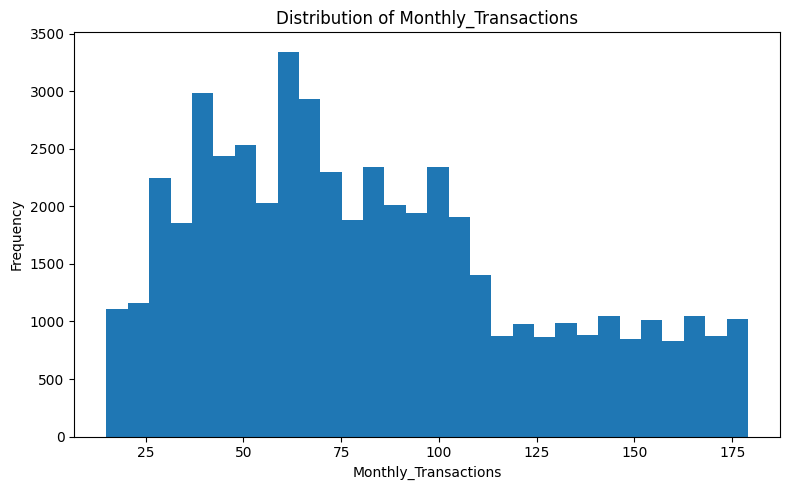

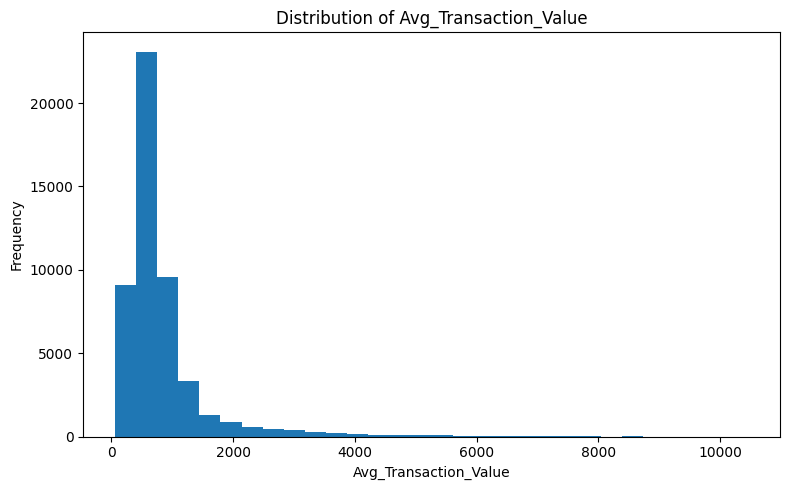

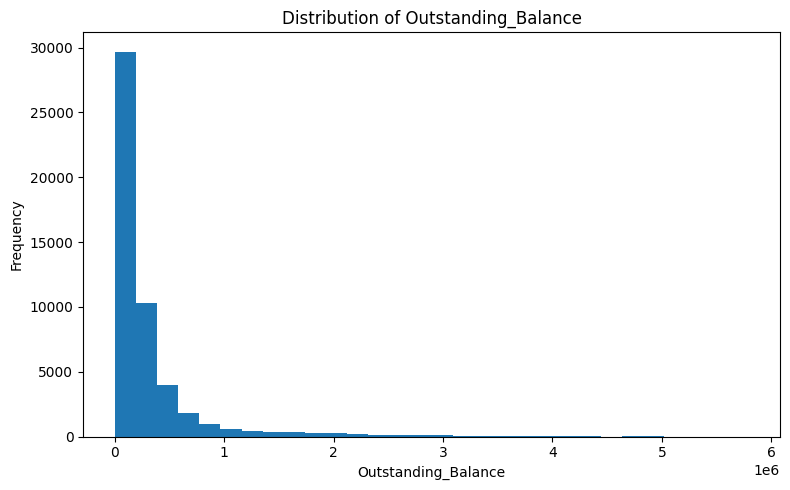

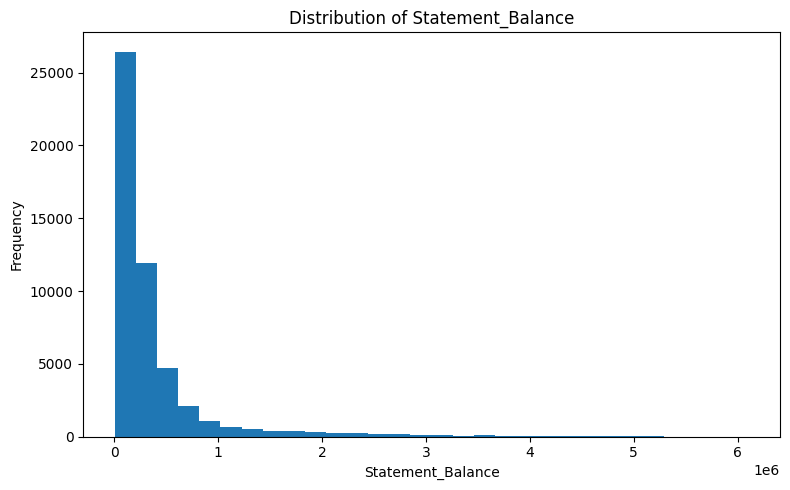

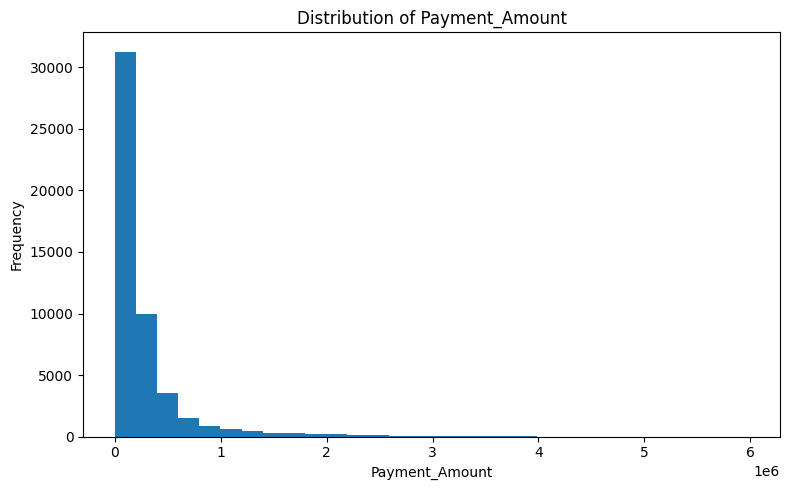

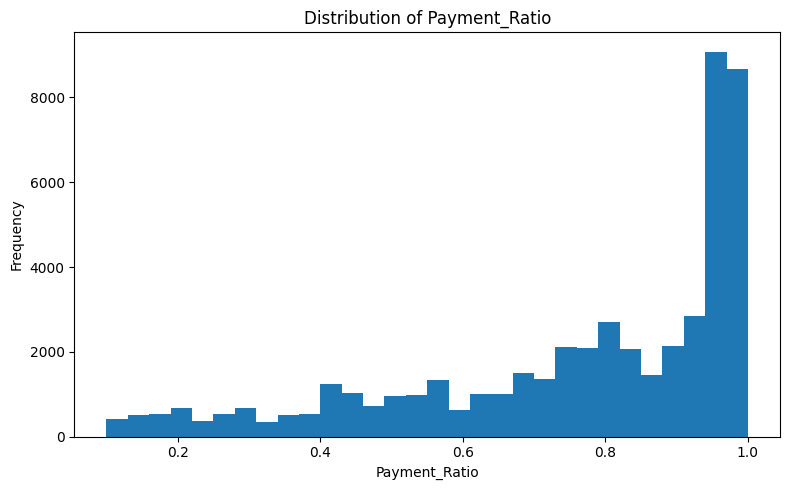

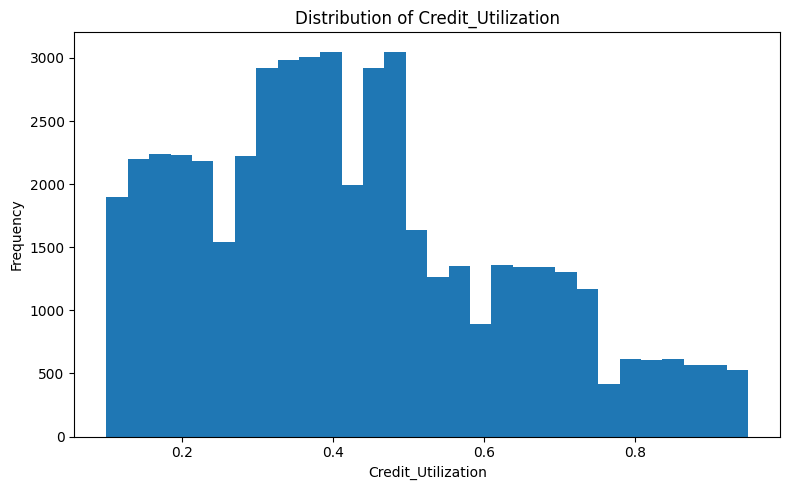

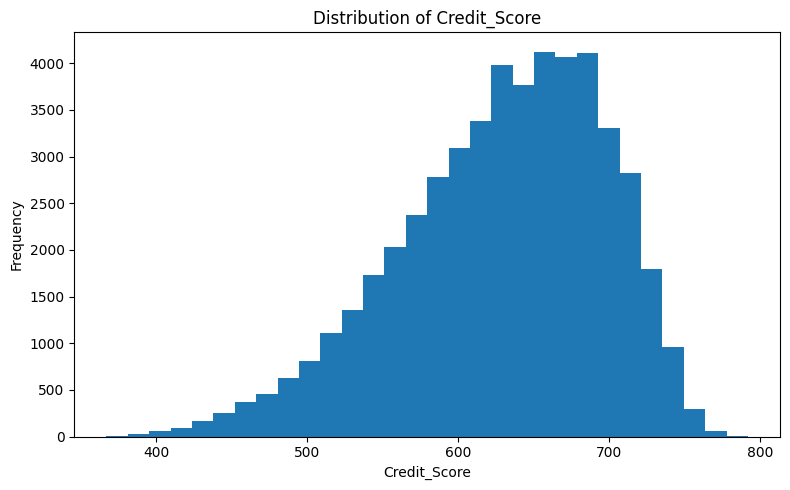

In [8]:
for col in eda_numeric_cols:
    plt.figure(figsize=(8, 5))
    plt.hist(df[col], bins=30)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

In [9]:
original_df = pd.read_csv(
    "../data/raw/synthetic_credit_card_customer_behavior_dataset.csv"
)

removed_columns = original_df.columns.difference(df.columns)

print("Original columns:", len(original_df.columns))
print("Cleaned columns:", len(df.columns))
print("Removed columns:", len(removed_columns))
print("Removed column names:")
print(removed_columns.tolist())

Original columns: 30
Cleaned columns: 30
Removed columns: 0
Removed column names:
[]


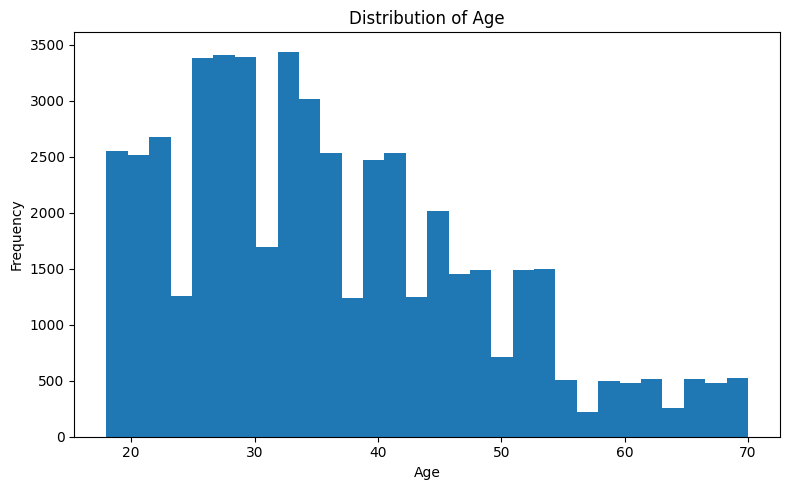

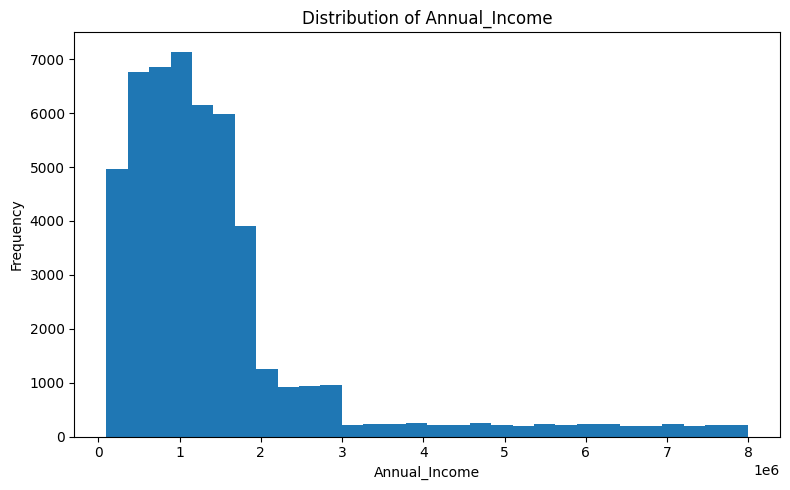

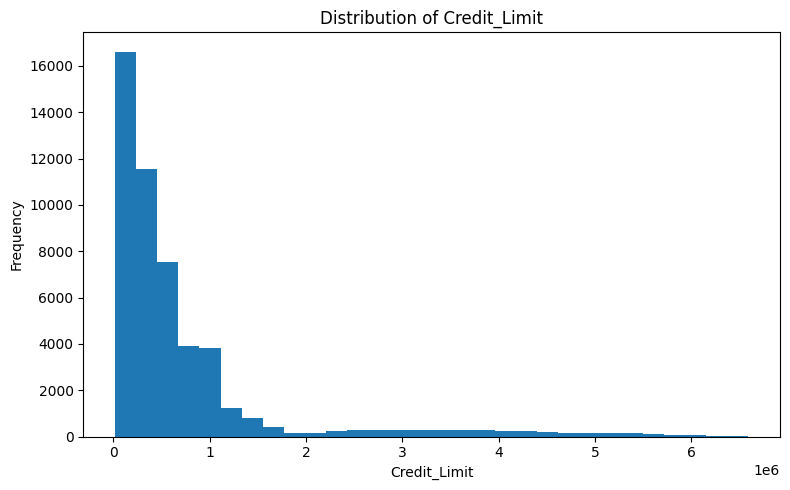

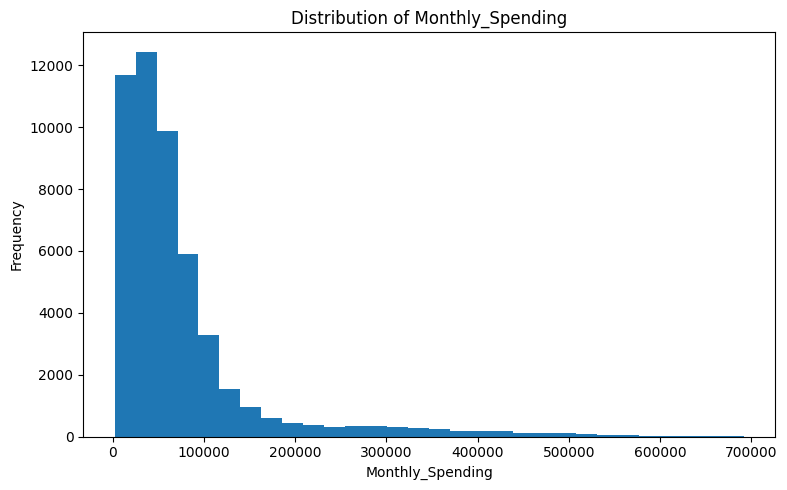

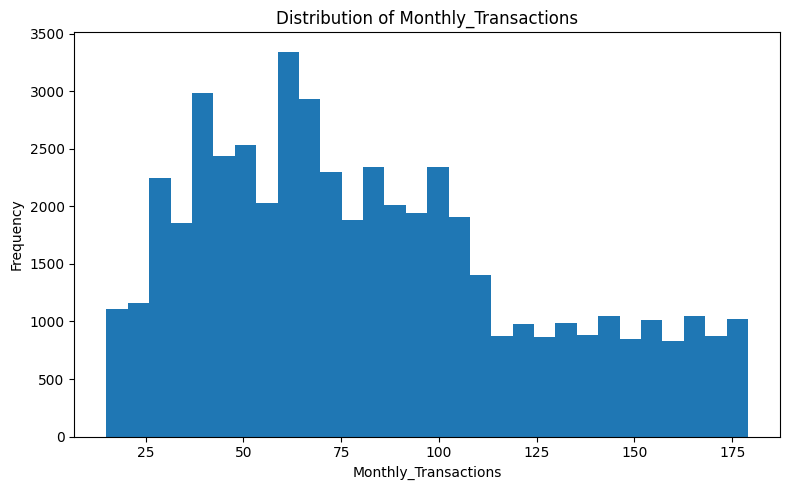

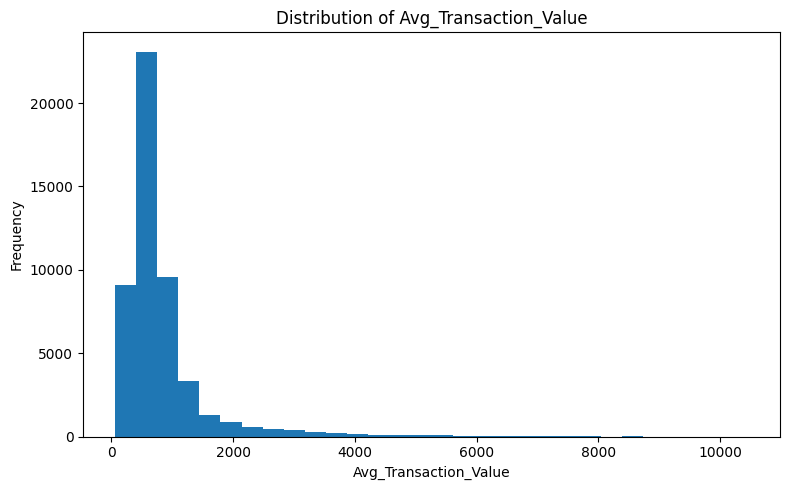

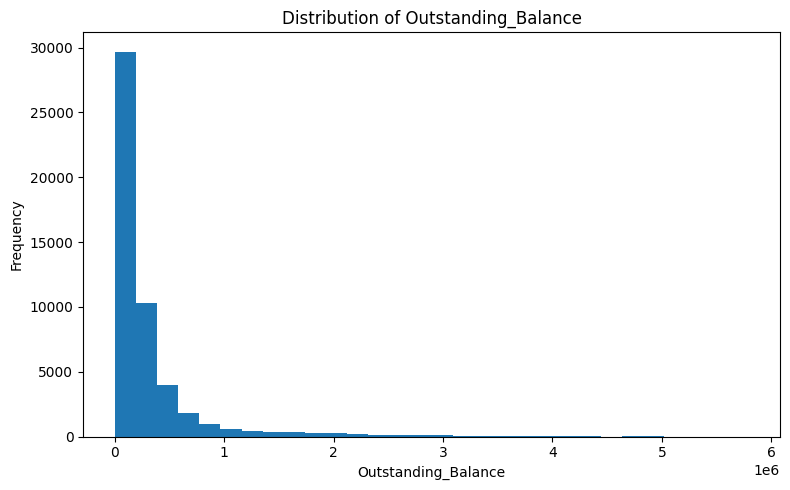

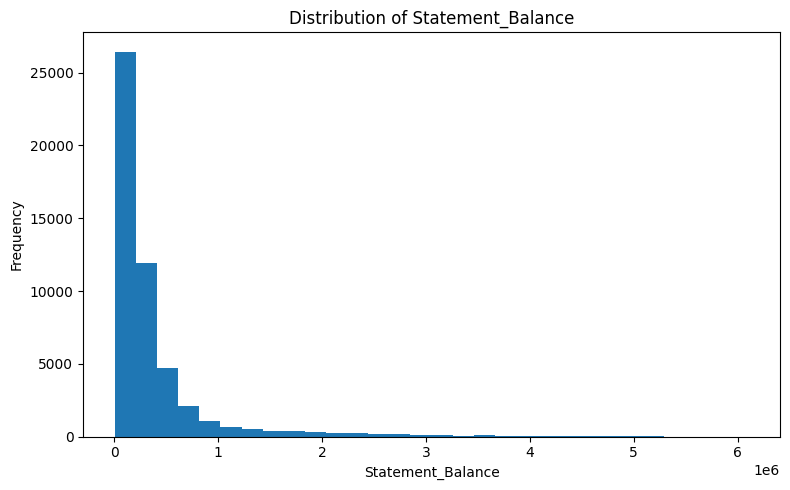

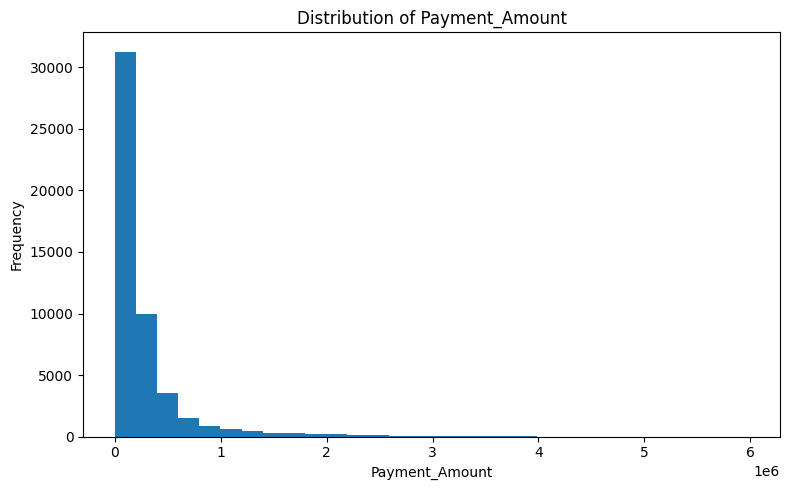

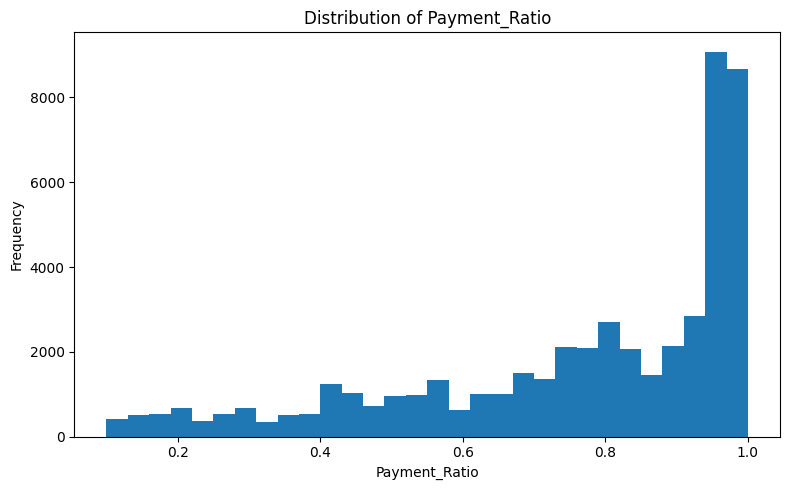

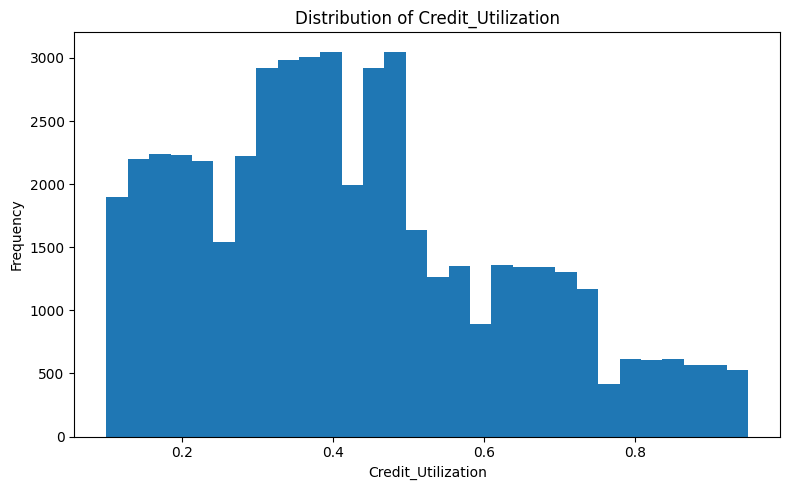

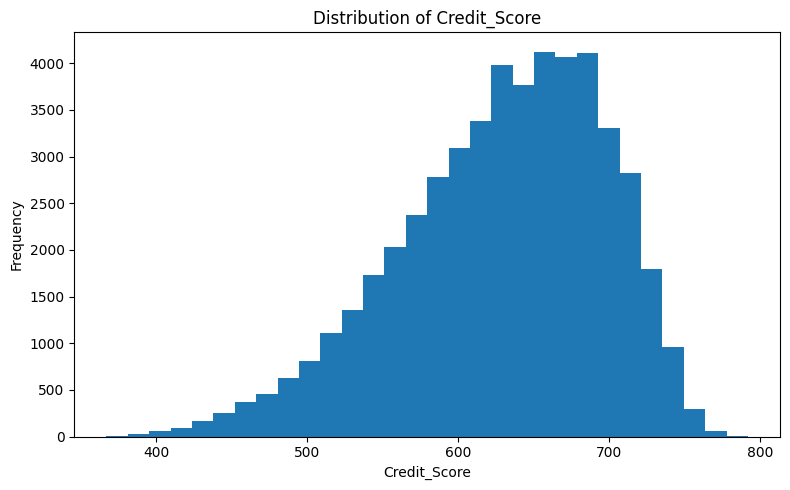

In [10]:
eda_numeric_cols = [
    "Age",
    "Annual_Income",
    "Credit_Limit",
    "Monthly_Spending",
    "Monthly_Transactions",
    "Avg_Transaction_Value",
    "Outstanding_Balance",
    "Statement_Balance",
    "Payment_Amount",
    "Payment_Ratio",
    "Credit_Utilization",
    "Credit_Score"
]

for col in eda_numeric_cols:
    plt.figure(figsize=(8, 5))
    plt.hist(df[col], bins=30)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

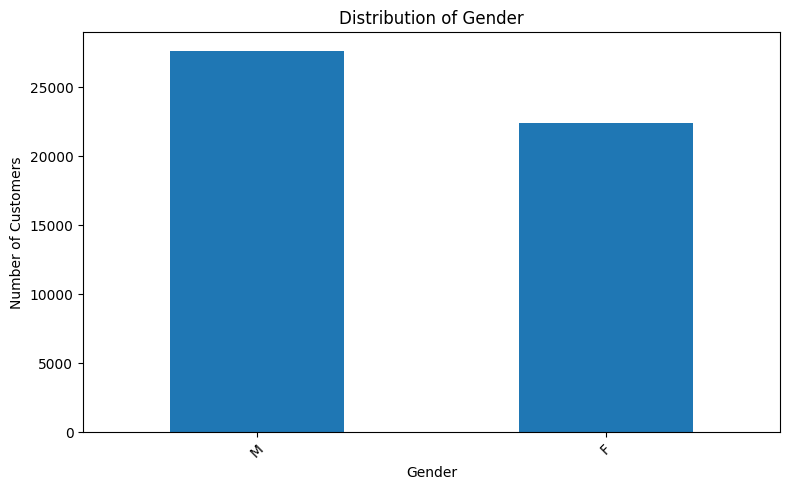

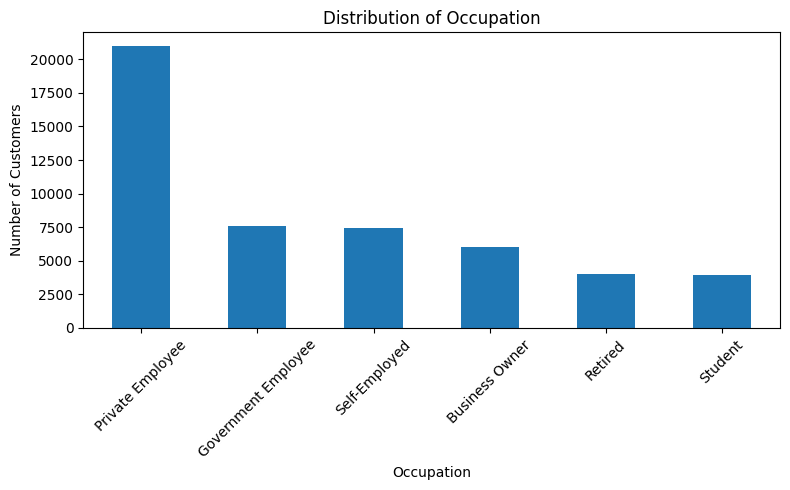

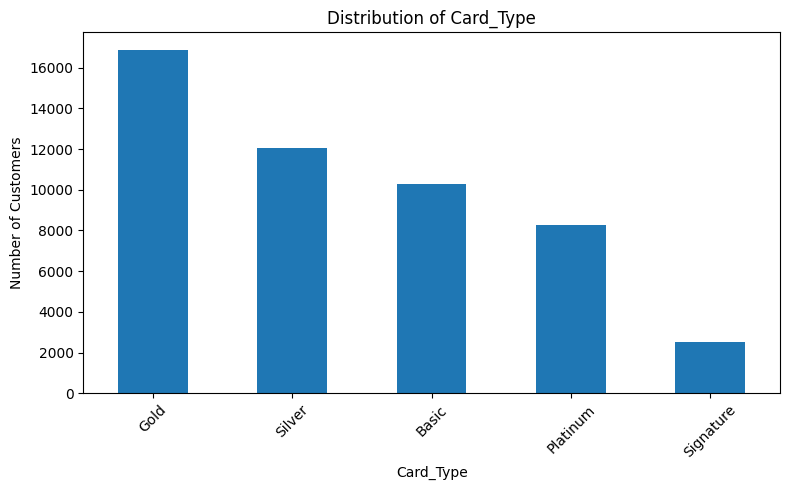

In [11]:
# Categorical feature distributions

for col in categorical_cols:
    counts = df[col].value_counts()

    plt.figure(figsize=(8, 5))
    counts.plot(kind="bar")

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Number of Customers")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

In [12]:
# Skewness analysis

skewness = df[numeric_cols].skew().sort_values(ascending=False)

skewness_df = pd.DataFrame({
    "skewness": skewness
})

skewness_df

,skewness
Cash_Advance_Amount,6.780405
Reward_Points_Redeemed,6.549172
Travel_Spending,5.711387
Entertainment_Spending,5.010933
Fuel_Spending,4.686787
Dining_Spending,4.642110
Online_Shopping_Spending,4.555631
Utility_Bill_Spending,4.345903
Payment_Amount,4.202547
Outstanding_Balance,4.020264


In [13]:
# Identify highly skewed numerical variables

highly_skewed = skewness_df[
    skewness_df["skewness"].abs() > 1
]

highly_skewed

,skewness
Cash_Advance_Amount,6.780405
Reward_Points_Redeemed,6.549172
Travel_Spending,5.711387
Entertainment_Spending,5.010933
Fuel_Spending,4.686787
Dining_Spending,4.642110
Online_Shopping_Spending,4.555631
Utility_Bill_Spending,4.345903
Payment_Amount,4.202547
Outstanding_Balance,4.020264


In [14]:
# Correlation matrix

correlation_matrix = df[numeric_cols].corr()

correlation_matrix

,Age,Annual_Income,Credit_Limit,Card_Age_Months,Monthly_Spending,Monthly_Transactions,Avg_Transaction_Value,Online_Shopping_Spending,Grocery_Spending,Fuel_Spending,...,Payment_Amount,Payment_Ratio,Credit_Utilization,Cash_Advance_Amount,EMI_Count,International_Transactions,Reward_Points_Earned,Reward_Points_Redeemed,Mobile_App_Login,Credit_Score
Age,1.000000,-0.009520,-0.010660,0.008414,-0.008676,-0.007879,-0.004849,-0.009378,-0.007579,-0.015538,...,-0.009845,-0.001243,-0.002267,-0.004214,-0.003614,-0.009499,-0.009207,-0.005224,-0.003636,0.000453
Annual_Income,-0.009520,1.000000,0.974166,-0.006956,0.945058,0.491985,0.831726,0.734074,0.809420,0.722605,...,0.819428,0.001793,0.004786,0.409345,0.472170,0.641996,0.923664,0.563082,0.583891,0.032349
Credit_Limit,-0.010660,0.974166,1.000000,-0.006347,0.940347,0.433834,0.834892,0.732373,0.804263,0.719683,...,0.838509,0.001160,0.004832,0.418390,0.413801,0.685757,0.958116,0.584344,0.522516,0.035457
Card_Age_Months,0.008414,-0.006956,-0.006347,1.000000,-0.006338,-0.004379,-0.008516,-0.005750,-0.008533,-0.002279,...,-0.006160,-0.004942,0.000318,-0.003294,-0.000899,-0.006173,-0.005767,-0.000963,-0.004723,0.052150
Monthly_Spending,-0.008676,0.945058,0.940347,-0.006338,1.000000,0.485919,0.882232,0.775293,0.856672,0.766482,...,0.804548,0.003121,0.005228,0.393812,0.461461,0.630797,0.979685,0.604527,0.578814,0.033214
Monthly_Transactions,-0.007879,0.491985,0.433834,-0.004379,0.485919,1.000000,0.135502,0.376220,0.413828,0.365141,...,0.377666,0.010989,0.005179,0.184211,0.565467,0.388662,0.413664,0.253555,0.649408,0.021293
Avg_Transaction_Value,-0.004849,0.831726,0.834892,-0.008516,0.882232,0.135502,1.000000,0.685421,0.757627,0.679366,...,0.708165,0.000106,0.002770,0.346377,0.349469,0.537223,0.873358,0.542361,0.443664,0.027644
Online_Shopping_Spending,-0.009378,0.734074,0.732373,-0.005750,0.775293,0.376220,0.685421,1.000000,0.581196,0.520466,...,0.623056,-0.000990,0.001476,0.302937,0.356899,0.485808,0.760317,0.456780,0.450850,0.024983
Grocery_Spending,-0.007579,0.809420,0.804263,-0.008533,0.856672,0.413828,0.757627,0.581196,1.000000,0.577473,...,0.678361,0.000735,0.000673,0.328746,0.393407,0.539285,0.838577,0.527049,0.494581,0.029442
Fuel_Spending,-0.015538,0.722605,0.719683,-0.002279,0.766482,0.365141,0.679366,0.520466,0.577473,1.000000,...,0.614698,0.004345,0.001779,0.314431,0.349275,0.481074,0.750739,0.451843,0.432610,0.027114


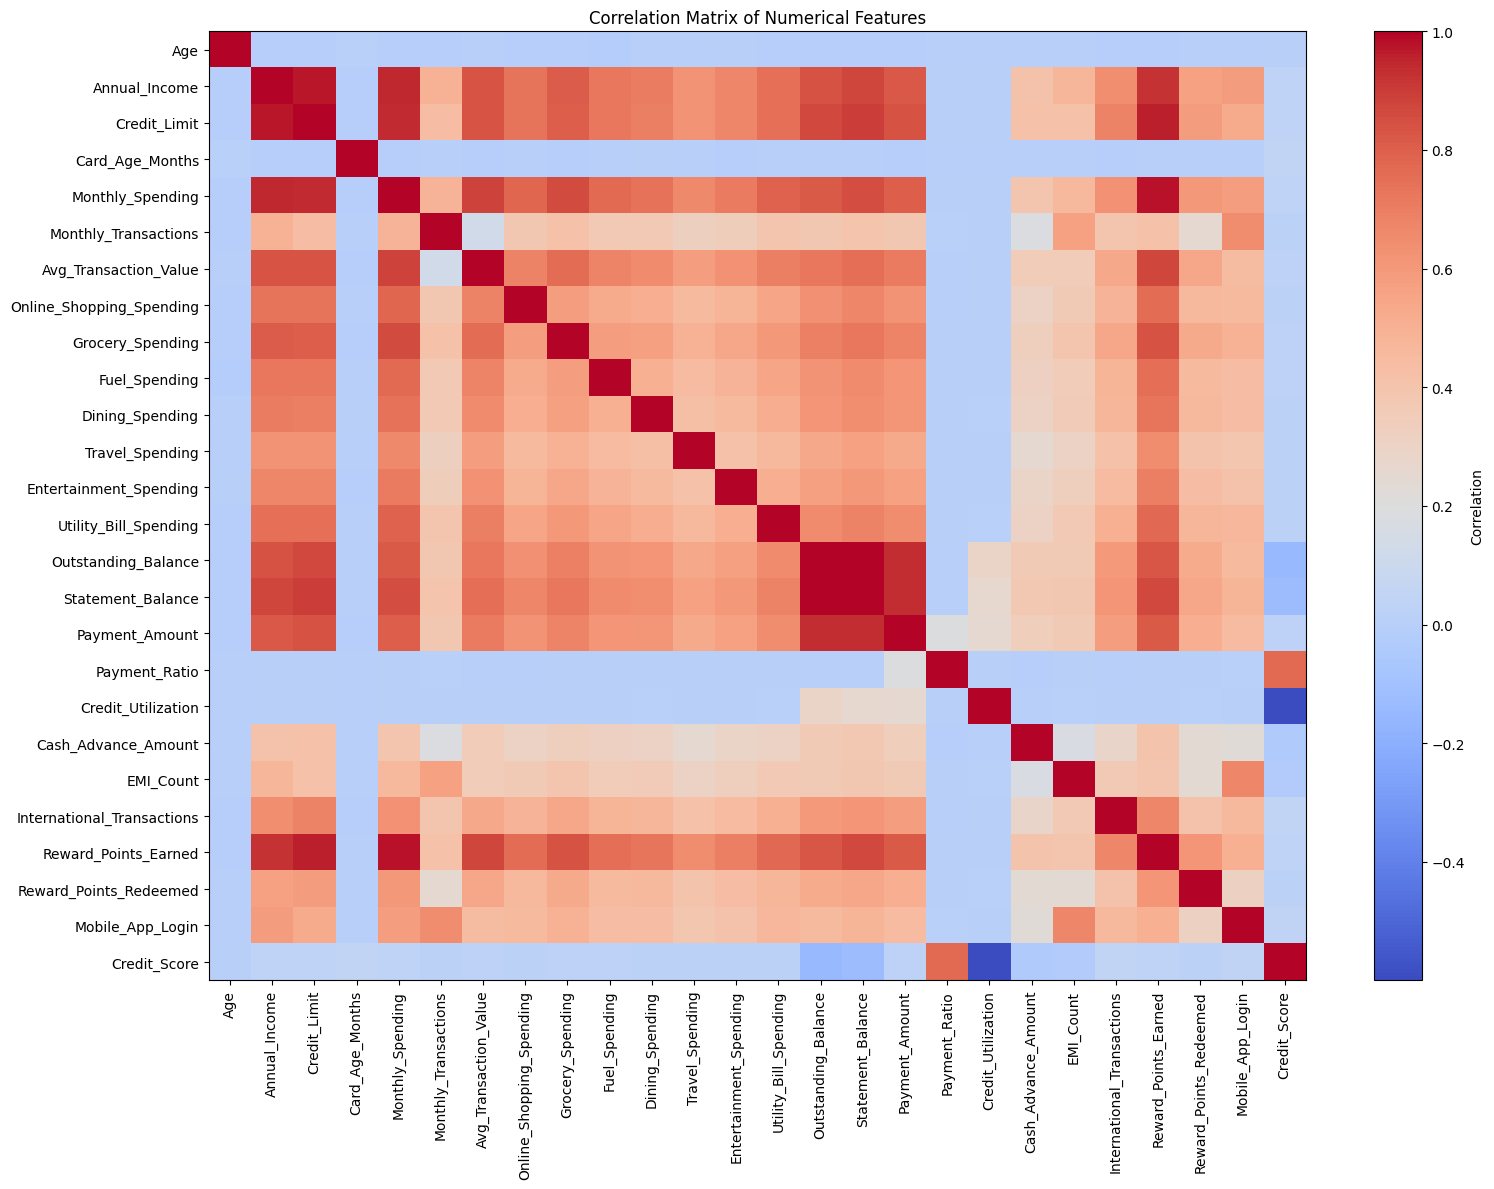

In [15]:
# Correlation heatmap

plt.figure(figsize=(16, 12))

plt.imshow(correlation_matrix, cmap="coolwarm", aspect="auto")
plt.colorbar(label="Correlation")

plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=90
)

plt.yticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns
)

plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()
plt.show()

In [16]:
# Correlation of numerical features with Credit Score

credit_score_corr = (
    df[numeric_cols]
    .corr()["Credit_Score"]
    .drop("Credit_Score")
    .sort_values(key=abs, ascending=False)
)

credit_score_corr

Payment_Ratio                 0.767146
Credit_Utilization           -0.599338
Outstanding_Balance          -0.145411
Statement_Balance            -0.125465
Card_Age_Months               0.052150
International_Transactions    0.050387
Mobile_App_Login              0.038828
Reward_Points_Earned          0.036081
Credit_Limit                  0.035457
Monthly_Spending              0.033214
Annual_Income                 0.032349
Payment_Amount                0.031100
Cash_Advance_Amount          -0.031019
Grocery_Spending              0.029442
EMI_Count                    -0.027918
Avg_Transaction_Value         0.027644
Fuel_Spending                 0.027114
Utility_Bill_Spending         0.025339
Online_Shopping_Spending      0.024983
Entertainment_Spending        0.023722
Dining_Spending               0.022631
Travel_Spending               0.022339
Monthly_Transactions          0.021293
Reward_Points_Redeemed        0.019441
Age                           0.000453
Name: Credit_Score, dtype

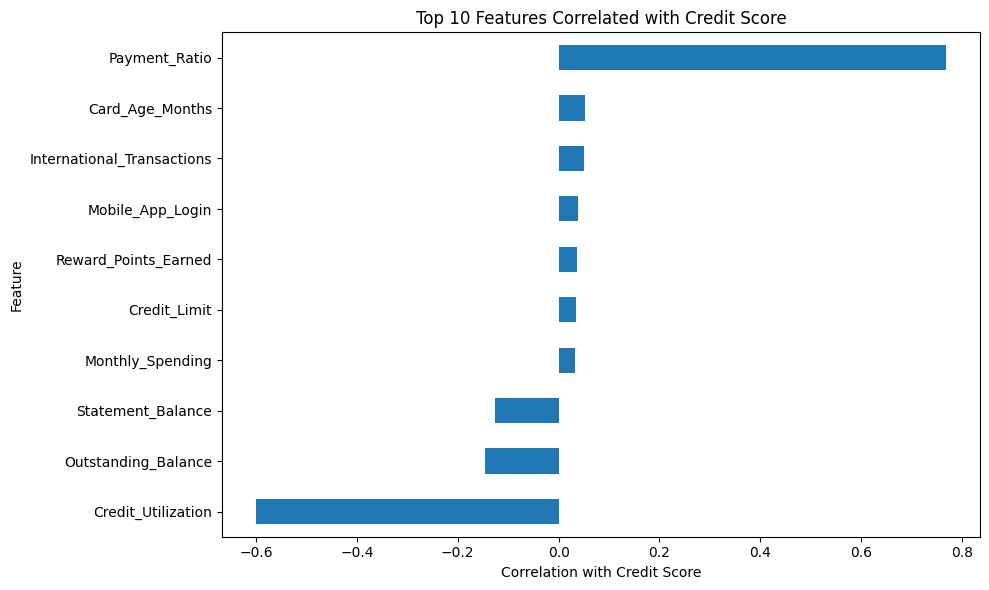

In [17]:
# Top 10 correlations with Credit Score

top_credit_score_corr = credit_score_corr.head(10)

plt.figure(figsize=(10, 6))

top_credit_score_corr.sort_values().plot(kind="barh")

plt.title("Top 10 Features Correlated with Credit Score")
plt.xlabel("Correlation with Credit Score")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

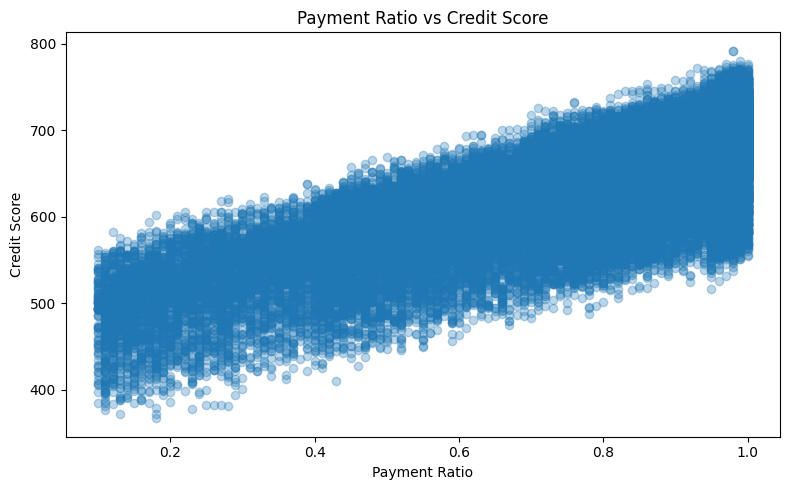

In [18]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Payment_Ratio"],
    df["Credit_Score"],
    alpha=0.3
)

plt.title("Payment Ratio vs Credit Score")
plt.xlabel("Payment Ratio")
plt.ylabel("Credit Score")

plt.tight_layout()
plt.show()

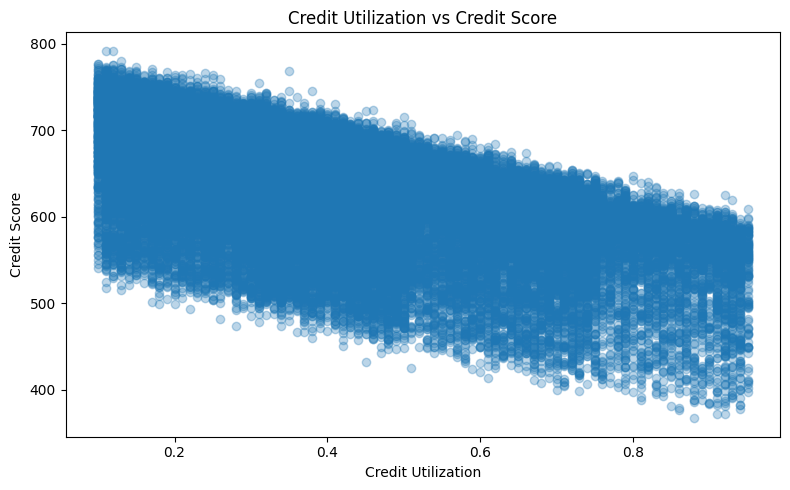

In [19]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Credit_Utilization"],
    df["Credit_Score"],
    alpha=0.3
)

plt.title("Credit Utilization vs Credit Score")
plt.xlabel("Credit Utilization")
plt.ylabel("Credit Score")

plt.tight_layout()
plt.show()

In [20]:
# Average Credit Score by categorical features

for col in categorical_cols:
    avg_score = df.groupby(col)["Credit_Score"].mean().sort_values(ascending=False)

    print(f"\nAverage Credit Score by {col}:")
    print(avg_score)


Average Credit Score by Gender:
Gender
M    629.467509
F    628.389157
Name: Credit_Score, dtype: float64

Average Credit Score by Occupation:
Occupation
Business Owner         633.572541
Self-Employed          630.464651
Government Employee    628.996708
Student                628.826276
Private Employee       627.690315
Retired                626.252286
Name: Credit_Score, dtype: float64

Average Credit Score by Card_Type:
Card_Type
Signature    637.317093
Platinum     634.230324
Basic        628.517688
Silver       627.133461
Gold         626.782007
Name: Credit_Score, dtype: float64


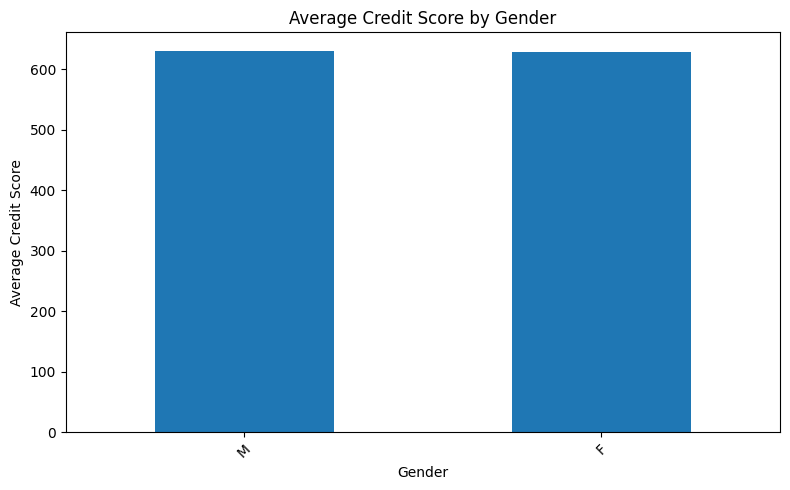

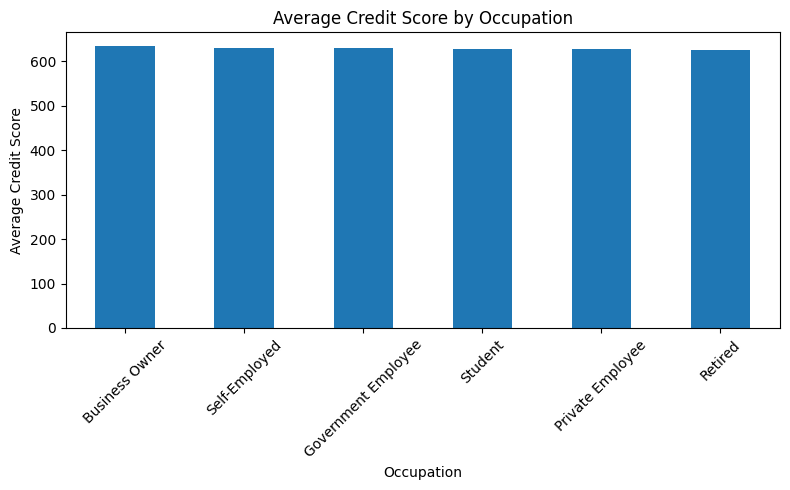

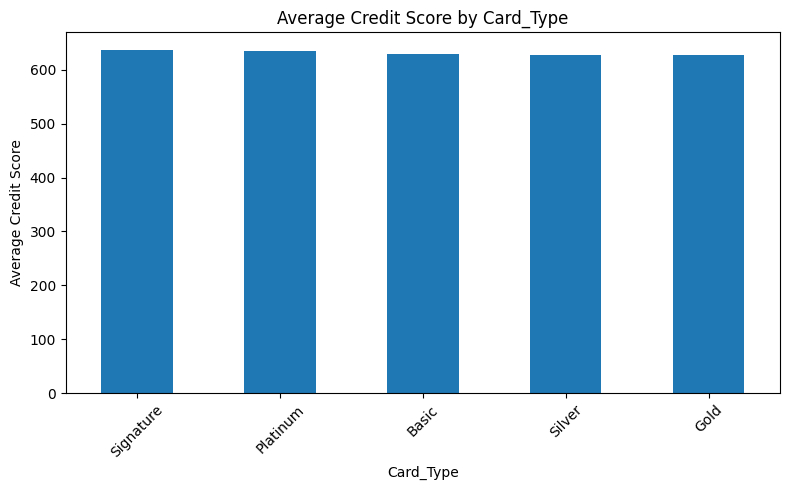

In [22]:
# Visualize average Credit Score by categorical features

for col in categorical_cols:
    avg_score = df.groupby(col)["Credit_Score"].mean().sort_values(ascending=False)

    plt.figure(figsize=(8, 5))
    avg_score.plot(kind="bar")

    plt.title(f"Average Credit Score by {col}")
    plt.xlabel(col)
    plt.ylabel("Average Credit Score")
    plt.xticks(rotation=45)

    plt.tight_layout()
    plt.show()

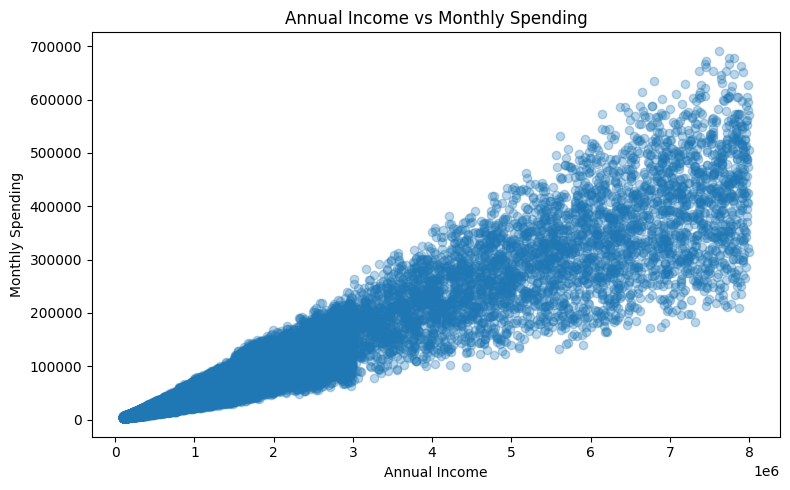

In [23]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Annual_Income"],
    df["Monthly_Spending"],
    alpha=0.3
)

plt.title("Annual Income vs Monthly Spending")
plt.xlabel("Annual Income")
plt.ylabel("Monthly Spending")

plt.tight_layout()
plt.show()

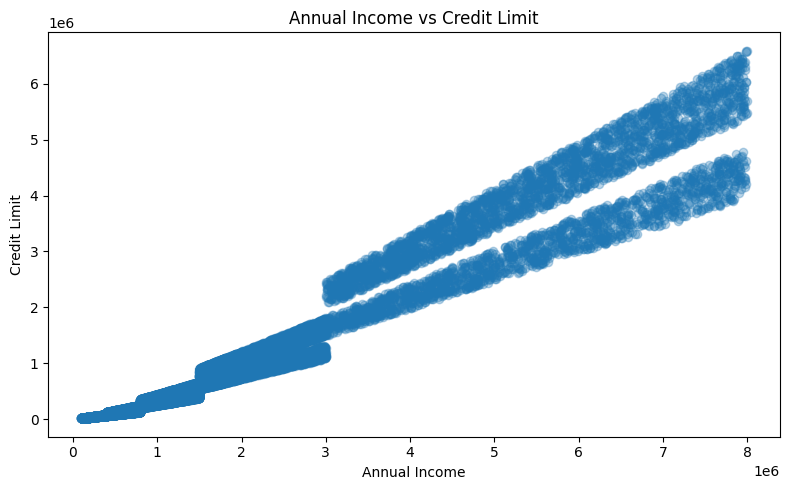

In [24]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Annual_Income"],
    df["Credit_Limit"],
    alpha=0.3
)

plt.title("Annual Income vs Credit Limit")
plt.xlabel("Annual Income")
plt.ylabel("Credit Limit")

plt.tight_layout()
plt.show()

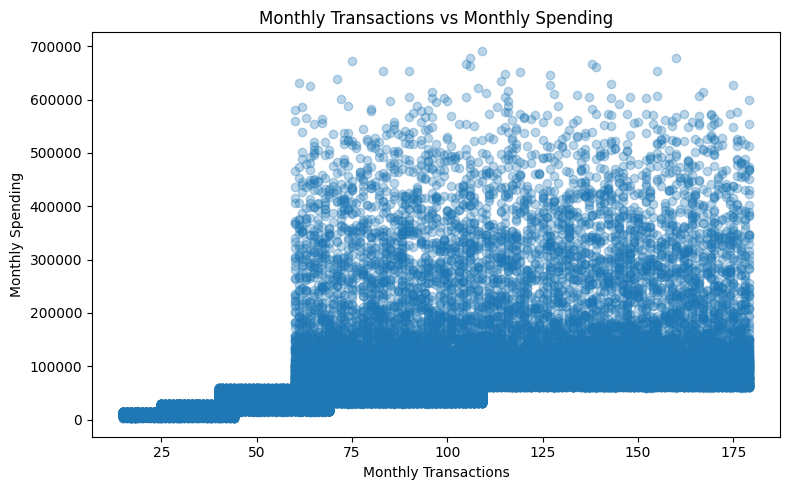

In [25]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Monthly_Transactions"],
    df["Monthly_Spending"],
    alpha=0.3
)

plt.title("Monthly Transactions vs Monthly Spending")
plt.xlabel("Monthly Transactions")
plt.ylabel("Monthly Spending")

plt.tight_layout()
plt.show()

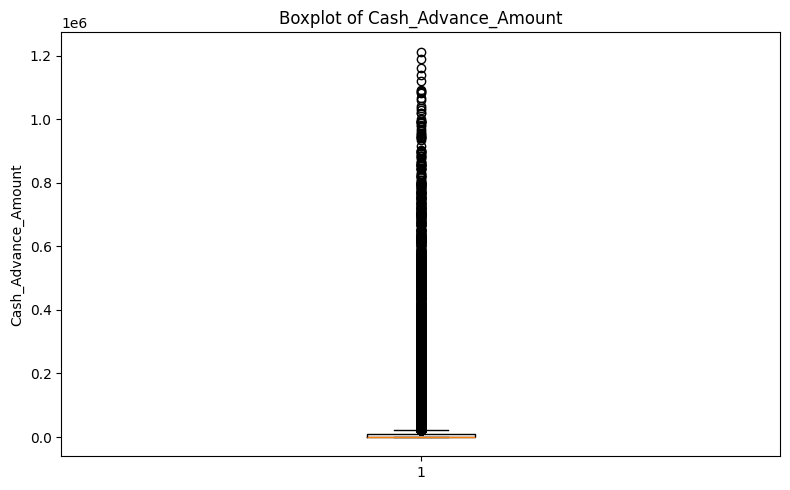

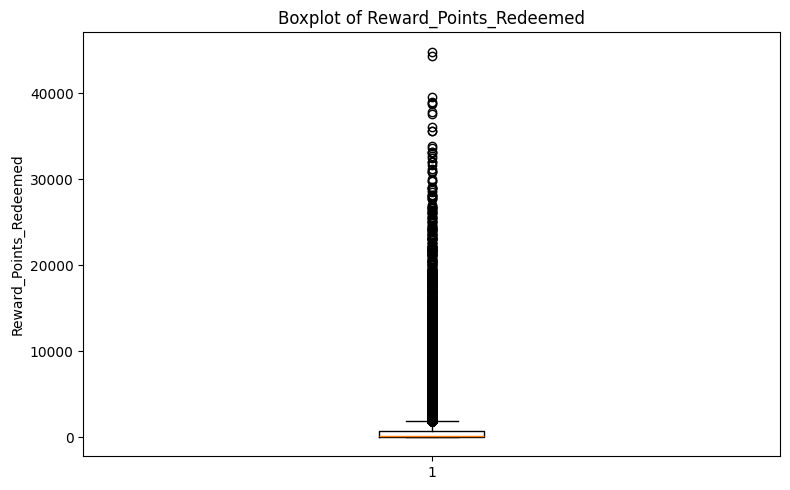

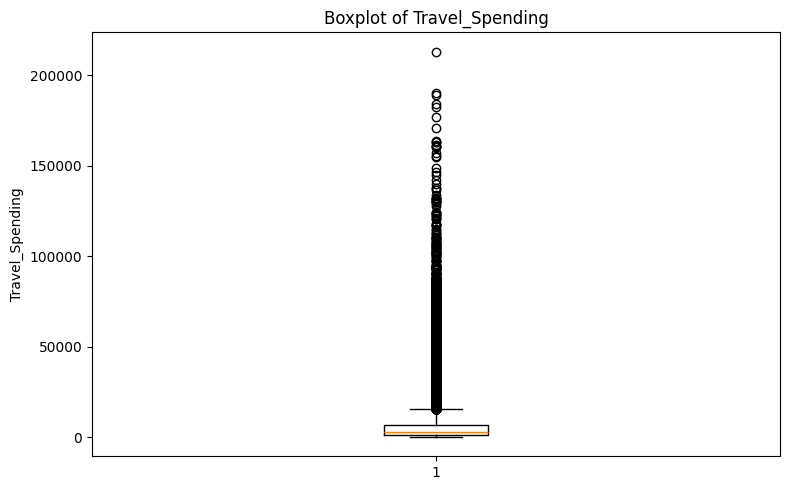

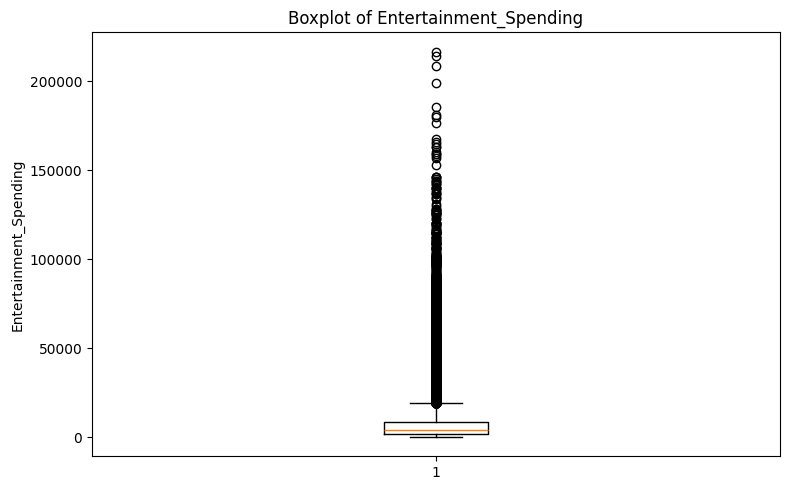

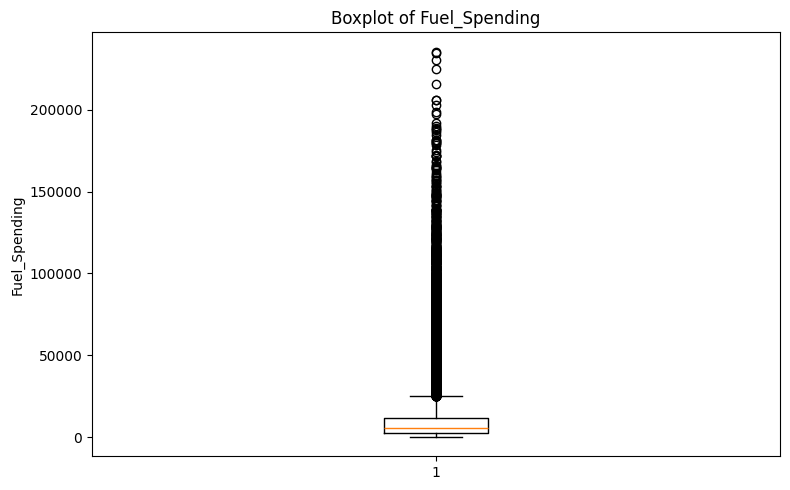

In [26]:
# Visualize distributions of highly skewed variables

skewed_features = [
    "Cash_Advance_Amount",
    "Reward_Points_Redeemed",
    "Travel_Spending",
    "Entertainment_Spending",
    "Fuel_Spending"
]

for col in skewed_features:
    plt.figure(figsize=(8, 5))

    plt.boxplot(df[col].dropna())

    plt.title(f"Boxplot of {col}")
    plt.ylabel(col)

    plt.tight_layout()
    plt.show()